In [44]:
import pandas as pd

In [45]:
column_names = [
    'mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
    'acceleration', 'model_year', 'origin', 'car_name'
]

df = pd.read_csv(r"C:\Users\Ruslan\Desktop\auto-mpg.data-original",
    sep=r'\s+',
    header=None,
    names=column_names,
    na_values=['?', 'NA'],
)

df['origin'] = df['origin'].map({1: 'USA', 2: 'Europe', 3: 'Japan'})
df['brand'] = df['car_name'].str.split().str[0]

In [46]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,brand
0,18.0,8.0,307.0,130.0,3504.0,12.0,70.0,USA,chevrolet chevelle malibu,chevrolet
1,15.0,8.0,350.0,165.0,3693.0,11.5,70.0,USA,buick skylark 320,buick
2,18.0,8.0,318.0,150.0,3436.0,11.0,70.0,USA,plymouth satellite,plymouth
3,16.0,8.0,304.0,150.0,3433.0,12.0,70.0,USA,amc rebel sst,amc
4,17.0,8.0,302.0,140.0,3449.0,10.5,70.0,USA,ford torino,ford


In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 406 entries, 0 to 405
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     406 non-null    float64
 2   displacement  406 non-null    float64
 3   horsepower    400 non-null    float64
 4   weight        406 non-null    float64
 5   acceleration  406 non-null    float64
 6   model_year    406 non-null    float64
 7   origin        406 non-null    str    
 8   car_name      406 non-null    str    
 9   brand         406 non-null    object 
dtypes: float64(7), object(1), str(2)
memory usage: 31.8+ KB


In [48]:
df.isnull().sum()

mpg             8
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
brand           0
dtype: int64

In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# mpg degeri olmayan satirlar hedefden istifade ede bilmediyi ucun cixarilir.
df_model = df.dropna(subset=['mpg']).copy()
numeric_features = [
    'cylinders', 'displacement', 'horsepower',
    'weight', 'acceleration', 'model_year'
]
X = df_model.drop(columns=['mpg', 'car_name', 'brand'])
y = df_model['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Imputer, scaler ve encoder her CV fold-da yalniz train hissede fit olunur.
# OneHotEncoder pipeline daxilinde fit edildiyinden pd.get_dummies-dan daha leakage-safe-dir.
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('origin', OneHotEncoder(handle_unknown='ignore'), ['origin']),
])

model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge()),
])
param_grids = {
    'Ridge': {
        'model': [Ridge()],
        'model__alpha': [0.1, 1.0, 10.0, 100.0],
    },
    'Lasso': {
        'model': [Lasso(max_iter=20000)],
        'model__alpha': [0.001, 0.01, 0.1, 1.0],
    },
    'Random Forest': {
        'model': [RandomForestRegressor(random_state=42)],
        'model__n_estimators': [100, 300],
        'model__max_depth': [None, 5, 10],
        'model__min_samples_split': [2, 5],
    },
    'Gradient Boosting': {
        'model': [GradientBoostingRegressor(random_state=42)],
        'model__learning_rate': [0.03, 0.1],
        'model__max_depth': [2, 3],
        'model__n_estimators': [100, 200],
    },
}

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}
trained_models = {}
rows = []

for model_name, param_grid in param_grids.items():
    search = GridSearchCV(
        estimator=model_pipeline,
        param_grid=param_grid,
        scoring=scoring,
        refit='RMSE',
        cv=5,
        n_jobs=-1,
        return_train_score=False,
    )
    search.fit(X_train, y_train)
    best_idx = search.best_index_
    test_predictions = search.best_estimator_.predict(X_test)
    trained_models[model_name] = search.best_estimator_

    cv_mae = -search.cv_results_['mean_test_MAE'][best_idx]
    cv_rmse = -search.cv_results_['mean_test_RMSE'][best_idx]
    cv_r2 = search.cv_results_['mean_test_R2'][best_idx]
    test_mae = mean_absolute_error(y_test, test_predictions)
    test_rmse = mean_squared_error(y_test, test_predictions) ** 0.5
    test_r2 = r2_score(y_test, test_predictions)
    rows.append({
        'Model': model_name,
        'CV MAE': cv_mae,
        'Test MAE': test_mae,
        'CV RMSE': cv_rmse,
        'Test RMSE': test_rmse,
        'RMSE Gap': abs(test_rmse - cv_rmse),
        'CV R2': cv_r2,
        'Test R2': test_r2,
        'Best Parameters': search.best_params_,
    })

results_df = pd.DataFrame(rows).set_index('Model').sort_values('Test RMSE')
display(results_df.round(3))

# Test RMSE model secimi ucun deyil; yalniz yekun, untouched qiymetlendirme ucundur.
stable_model = results_df['RMSE Gap'].idxmin()
best_test_model = results_df['Test RMSE'].idxmin()
print(f'CV ve test RMSE arasindaki en kicik ferq: {stable_model}')
print(f'En asagi test RMSE: {best_test_model}')

,CV MAE,Test MAE,CV RMSE,Test RMSE,RMSE Gap,CV R2,Test R2,Best Parameters
Model,,,,,,,,
Random Forest,2.161,1.588,3.083,2.171,0.912,0.845,0.912,"{'model': RandomForestRegressor(random_state=42), 'model__max_depth': 10, 'model__min_samples_split': 5, 'model__n_estimators': 300}"
Gradient Boosting,2.137,1.835,2.945,2.402,0.543,0.856,0.893,"{'model': GradientBoostingRegressor(random_state=42), 'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}"
Ridge,2.659,2.285,3.455,2.888,0.567,0.806,0.845,"{'model': Ridge(), 'model__alpha': 1.0}"
Lasso,2.659,2.284,3.457,2.900,0.558,0.805,0.844,"{'model': Lasso(max_iter=20000), 'model__alpha': 0.01}"


CV ve test RMSE arasindaki en kicik ferq: Gradient Boosting
En asagi test RMSE: Random Forest


In [50]:
import numpy as np
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from auto_mpg_transformers import AutoMPGFeatureEngineer, RareBrandGrouper

numeric_base = [
    'cylinders', 'displacement', 'horsepower',
    'weight', 'acceleration', 'model_year'
]
numeric_features = numeric_base + [
    'power_to_weight', 'disp_per_cyl', 'weight_per_cyl'
]

# mpg-si olmayan setirleri cixar, brand-i car_name-in ilk sozunden al.
df_model = df.dropna(subset=['mpg']).copy()
df_model['brand'] = df_model['car_name'].str.split().str[0].str.lower()
X = df_model.drop(columns=['mpg', 'car_name'])
y = df_model['mpg']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Imputer/scaler/encoder ve nadir brand qruplashdirma yalniz train fold-larinda fit olunur.
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
origin_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
brand_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('rare_to_other', RareBrandGrouper(min_count=5)),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('origin', origin_pipeline, ['origin']),
    ('brand', brand_pipeline, ['brand']),
])
base_pipeline = Pipeline([
    ('feature_engineering', AutoMPGFeatureEngineer()),
    ('preprocessing', preprocessor),
    ('model', RandomForestRegressor(random_state=42)),
])

model_spaces = {
    'XGBoost': (
        XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=1, tree_method='hist'),
        {
            'regressor__model__n_estimators': [150, 300, 500],
            'regressor__model__max_depth': [2, 3, 4],
            'regressor__model__learning_rate': [0.03, 0.07, 0.1],
            'regressor__model__subsample': [0.75, 0.9, 1.0],
            'regressor__model__colsample_bytree': [0.75, 0.9, 1.0],
            'regressor__model__reg_lambda': [1.0, 5.0, 10.0],
        },
    ),
    'LightGBM': (
        LGBMRegressor(random_state=42, verbosity=-1, n_jobs=1),
        {
            'regressor__model__n_estimators': [100, 250, 400],
            'regressor__model__learning_rate': [0.03, 0.07, 0.1],
            'regressor__model__max_depth': [-1, 3, 5],
            'regressor__model__num_leaves': [7, 15, 31],
            'regressor__model__min_child_samples': [5, 10, 15],
            'regressor__model__subsample': [0.75, 0.9, 1.0],
        },
    ),
    'Random Forest': (
        RandomForestRegressor(random_state=42, n_jobs=1),
        {
            'regressor__model__n_estimators': [150, 300, 500],
            'regressor__model__max_depth': [None, 5, 8, 12],
            'regressor__model__min_samples_split': [2, 5, 10],
            'regressor__model__min_samples_leaf': [1, 2, 4],
            'regressor__model__max_features': [0.7, 1.0],
        },
    ),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}
searches = {}
cv_rows = []
for model_name, (estimator, parameter_space) in model_spaces.items():
    pipeline = base_pipeline.set_params(model=estimator)
    for target_mode, target_func, inverse_func in [
        ('raw', None, None),
        ('log1p', np.log1p, np.expm1),
    ]:
        target_model = TransformedTargetRegressor(
            regressor=pipeline,
            func=target_func,
            inverse_func=inverse_func,
        )
        search = RandomizedSearchCV(
            estimator=target_model,
            param_distributions=parameter_space,
            n_iter=8,
            scoring=scoring,
            refit='RMSE',
            cv=cv,
            random_state=42,
            n_jobs=2,
            return_train_score=False,
        )
        search.fit(X_train, y_train)
        best_index = search.best_index_
        searches[(model_name, target_mode)] = search
        cv_rows.append({
            'Model': model_name,
            'Target': target_mode,
            'CV MAE': -search.cv_results_['mean_test_MAE'][best_index],
            'CV RMSE': -search.cv_results_['mean_test_RMSE'][best_index],
            'CV R2': search.cv_results_['mean_test_R2'][best_index],
        })

# Her model ailesi icin raw ve log1p hedefini yalniz CV neticesine gore sec.
best_by_family = {
    name: max(
        (searches[(name, mode)] for mode in ('raw', 'log1p')),
        key=lambda result: result.best_score_,
    )
    for name in model_spaces
}
top_three = sorted(
    best_by_family,
    key=lambda name: best_by_family[name].best_score_,
    reverse=True,
)[:3]
stacking_model = StackingRegressor(
    estimators=[
        (name.lower().replace(' ', '_'), best_by_family[name].best_estimator_)
        for name in top_three
    ],
    final_estimator=LinearRegression(),
    cv=cv,
    n_jobs=2,
)
stacking_model.fit(X_train, y_train)

def regression_metrics(actual, predicted):
    return {
        'Test MAE': mean_absolute_error(actual, predicted),
        'Test RMSE': mean_squared_error(actual, predicted) ** 0.5,
        'Test R2': r2_score(actual, predicted),
    }

# Baseline: onceki RF parametrlÉ™ri, eyni split ve yalniz evvelki xususiyyetler.
baseline_preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_base),
    ('origin', origin_pipeline, ['origin']),
])
baseline_columns = numeric_base + ['origin']
baseline_model = Pipeline([
    ('preprocessing', baseline_preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        n_jobs=1,
    )),
])
baseline_model.fit(X_train[baseline_columns], y_train)
comparison_rows = [{
    'Model': 'Baseline Random Forest',
    **regression_metrics(y_test, baseline_model.predict(X_test[baseline_columns])),
}]
for model_name in top_three:
    best_model = best_by_family[model_name].best_estimator_
    target_label = 'log1p' if best_model.func is not None else 'raw'
    comparison_rows.append({
        'Model': f'Tuned {model_name} ({target_label})',
        **regression_metrics(y_test, best_model.predict(X_test)),
    })
comparison_rows.append({
    'Model': 'Stacking top 3',
    **regression_metrics(y_test, stacking_model.predict(X_test)),
})
comparison_df = pd.DataFrame(comparison_rows).set_index('Model')
baseline_scores = comparison_df.loc['Baseline Random Forest']
for metric, direction in [('Test MAE', -1), ('Test RMSE', -1), ('Test R2', 1)]:
    comparison_df[f'{metric} Improvement %'] = (
        (comparison_df[metric] - baseline_scores[metric])
        / abs(baseline_scores[metric]) * 100 * direction
    )

print(f'Train rows: {len(X_train)} | Test rows: {len(X_test)}')
display(pd.DataFrame(cv_rows).sort_values(['Model', 'CV RMSE']).round(3))
display(comparison_df.round(3))
print(f'Top-3 stacking base models (selected by CV RMSE): {top_three}')

Train rows: 318 | Test rows: 80


,Model,Target,CV MAE,CV RMSE,CV R2
3,LightGBM,log1p,2.030,2.865,0.866
2,LightGBM,raw,2.087,2.919,0.861
5,Random Forest,log1p,2.034,2.911,0.861
4,Random Forest,raw,2.037,2.937,0.859
1,XGBoost,log1p,1.984,2.841,0.869
0,XGBoost,raw,2.010,2.850,0.868


,Test MAE,Test RMSE,Test R2,Test MAE Improvement %,Test RMSE Improvement %,Test R2 Improvement %
Model,,,,,,
Baseline Random Forest,1.588,2.171,0.912,-0.000,-0.000,0.000
Tuned XGBoost (log1p),1.736,2.288,0.903,-9.339,-5.384,-1.063
Tuned LightGBM (log1p),1.733,2.276,0.904,-9.123,-4.821,-0.949
Tuned Random Forest (log1p),1.551,2.039,0.923,2.301,6.070,1.131
Stacking top 3,1.626,2.135,0.915,-2.413,1.642,0.313


Top-3 stacking base models (selected by CV RMSE): ['XGBoost', 'LightGBM', 'Random Forest']


Model yadda saxlanildi ve yeniden yuklendi: best_auto_mpg_rf_model.pkl
Test metrikleri (mpg vahidinde):
Test MAE     1.551
Test RMSE    2.039
Test R2      0.923
Example car predicted MPG: 32.05


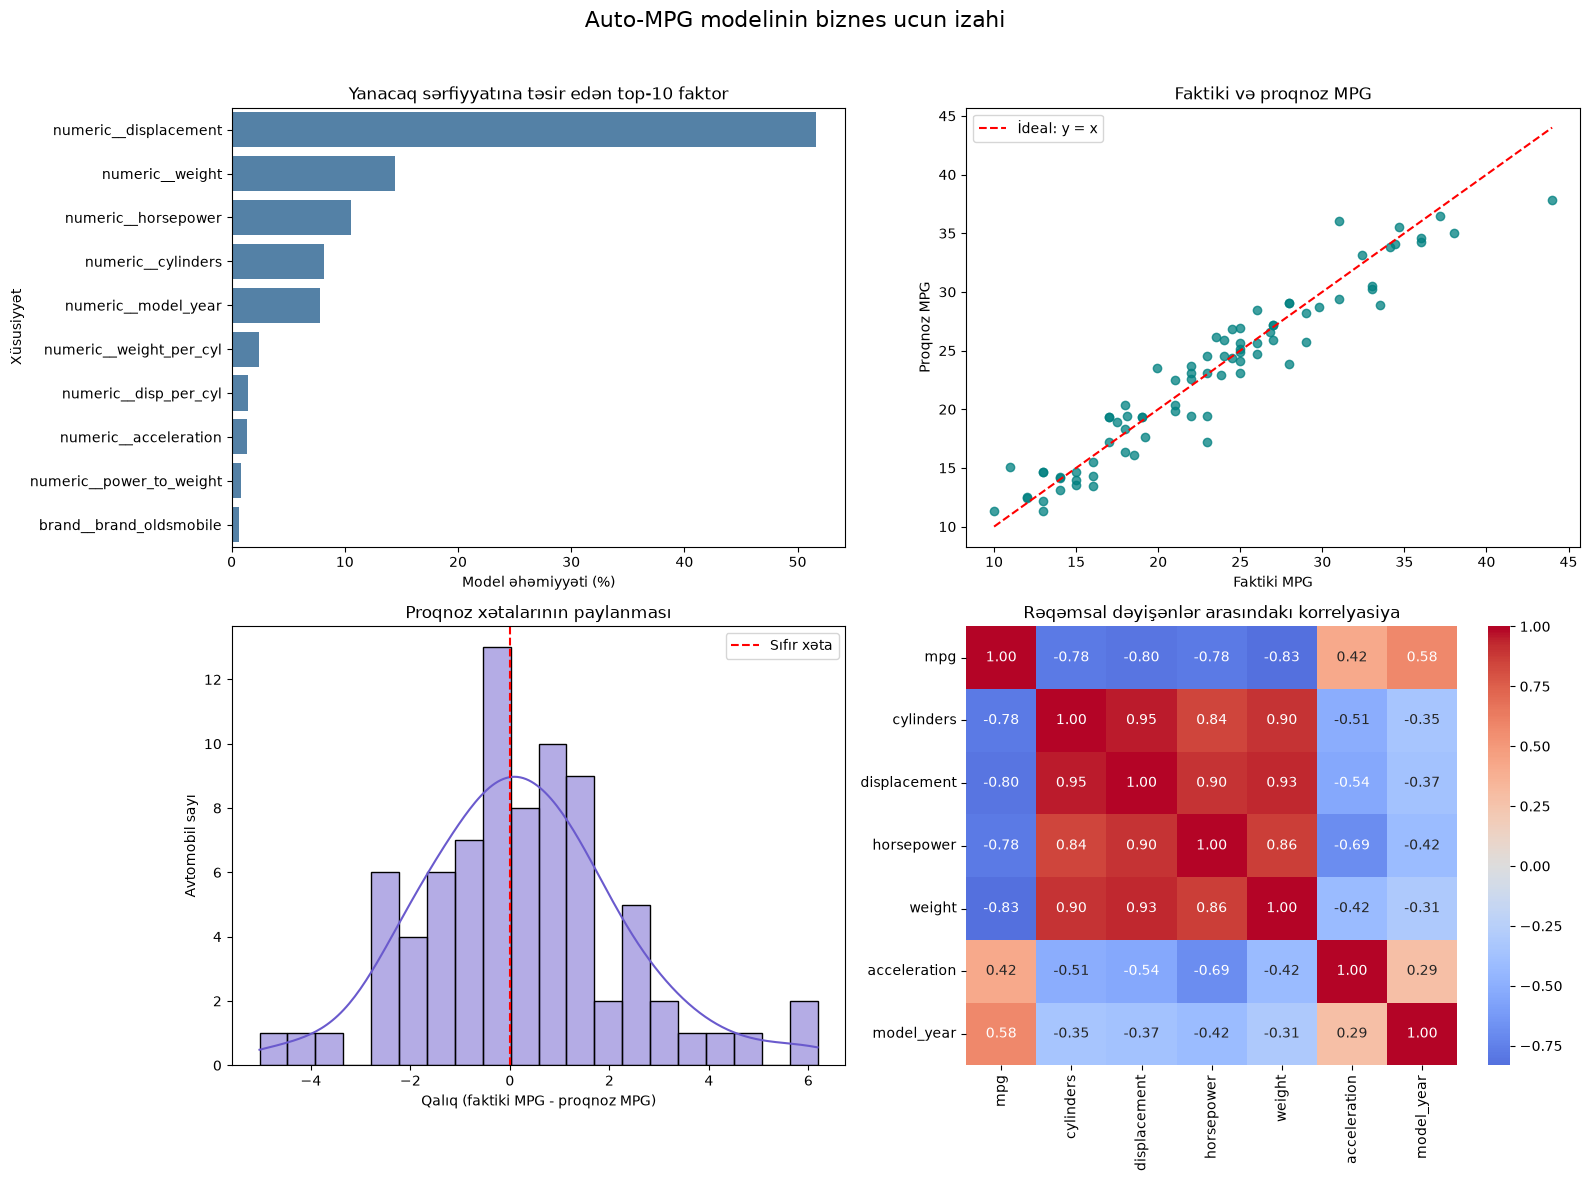


Biznes izahları:
1. Feature importance: ən yüksək faizli faktorlar mpg proqnozuna ən çox töhfə verən siqnallardır; bunları mühərrik/çəki və məhsul qərarları üçün prioritet kimi təqdim edin. Bu göstərici səbəb-nəticə sübutu deyil.
2. Faktiki vs proqnoz: nöqtələr qırmızı y=x xəttinə nə qədər yaxındırsa, model faktiki mpg-ni bir o qədər dəqiq təxmin edir; xəttdən sistemli yayınma optimallaşdırma siqnalıdır.
3. Residuals: qalıqların sıfır ətrafında və simmetrik olması sistemli over/under-prediction olmadığını göstərir; uzun quyruqlar və kənar qalıqlar xüsusi avtomobil qruplarının ayrıca yoxlanmasını tələb edir.
4. Korrelyasiya: mpg ilə güclü müsbət/mənfi xətti əlaqələr ilkin biznes hipotezi yaradır; korrelyasiya təkbaşına səbəb-nəticəni göstərmir.


In [51]:
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# CV ile secilmis log1p Random Forest pipeline-ni gotur.
rf_search = searches[('Random Forest', 'log1p')]
rf_target_model = rf_search.best_estimator_
rf_pipeline = rf_target_model.regressor_
model_path = 'best_auto_mpg_rf_model.pkl'
joblib.dump(rf_pipeline, model_path)

# Fayli geri yukle ve test setinde log1p proqnozlarini yoxla.
loaded_rf_pipeline = joblib.load(model_path)
test_log_predictions = loaded_rf_pipeline.predict(X_test)
test_predictions = np.expm1(test_log_predictions)
print(f'Model yadda saxlanildi ve yeniden yuklendi: {model_path}')
print('Test metrikleri (mpg vahidinde):')
print(pd.Series(regression_metrics(y_test, test_predictions)).round(3).to_string())

def predict_mpg(
    cylinders,
    displacement,
    horsepower,
    weight,
    acceleration,
    model_year,
    origin,
    brand,
    model=loaded_rf_pipeline,
):
    """Bir avtomobil ucun mpg proqnozunu qaytarir."""
    car = pd.DataFrame([{
        'cylinders': cylinders,
        'displacement': displacement,
        'horsepower': horsepower,
        'weight': weight,
        'acceleration': acceleration,
        'model_year': model_year,
        'origin': origin,
        'brand': brand,
    }])
    log_mpg_prediction = model.predict(car)[0]
    return float(np.expm1(log_mpg_prediction))

example_mpg = predict_mpg(
    cylinders=4,
    displacement=140,
    horsepower=90,
    weight=2400,
    acceleration=15.5,
    model_year=80,
    origin='USA',
    brand='ford',
)
print(f'Example car predicted MPG: {example_mpg:.2f}')

# Feature adlari ve vaciblik faizleri fitted preprocessing-den cixarilir.
feature_names = rf_pipeline.named_steps['preprocessing'].get_feature_names_out()
feature_importance = pd.Series(
    rf_pipeline.named_steps['model'].feature_importances_,
    index=feature_names,
)
feature_importance_pct = (feature_importance / feature_importance.sum() * 100).nlargest(10)
residuals = y_test.to_numpy() - test_predictions
numeric_correlation = df_model.select_dtypes(include='number').corr()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Auto-MPG modelinin biznes ucun izahi', fontsize=16)

# 1. Top-10 feature importance, faizle.
sns.barplot(
    x=feature_importance_pct.values,
    y=feature_importance_pct.index,
    ax=axes[0, 0],
    color='steelblue',
)
axes[0, 0].set_title('Yanacaq sərfiyyatına təsir edən top-10 faktor')
axes[0, 0].set_xlabel('Model əhəmiyyəti (%)')
axes[0, 0].set_ylabel('Xüsusiyyət')

# 2. Faktiki ve proqnoz mpg; qirmizi xett ideal proqnozdur.
axes[0, 1].scatter(y_test, test_predictions, alpha=0.75, color='teal')
axis_min = min(float(y_test.min()), float(test_predictions.min()))
axis_max = max(float(y_test.max()), float(test_predictions.max()))
axes[0, 1].plot([axis_min, axis_max], [axis_min, axis_max], 'r--', label='İdeal: y = x')
axes[0, 1].set_title('Faktiki və proqnoz MPG')
axes[0, 1].set_xlabel('Faktiki MPG')
axes[0, 1].set_ylabel('Proqnoz MPG')
axes[0, 1].legend()

# 3. Residual paylanmasi.
sns.histplot(residuals, bins=20, kde=True, ax=axes[1, 0], color='slateblue')
axes[1, 0].axvline(0, color='red', linestyle='--', label='Sıfır xəta')
axes[1, 0].set_title('Proqnoz xətalarının paylanması')
axes[1, 0].set_xlabel('Qalıq (faktiki MPG - proqnoz MPG)')
axes[1, 0].set_ylabel('Avtomobil sayı')
axes[1, 0].legend()

# 4. Rəqəmsal sütunların korrelyasiya heatmap-i.
sns.heatmap(
    numeric_correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    ax=axes[1, 1],
)
axes[1, 1].set_title('Rəqəmsal dəyişənlər arasındakı korrelyasiya')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print('\nBiznes izahları:')
print('1. Feature importance: ən yüksək faizli faktorlar mpg proqnozuna ən çox töhfə verən siqnallardır; bunları mühərrik/çəki və məhsul qərarları üçün prioritet kimi təqdim edin. Bu göstərici səbəb-nəticə sübutu deyil.')
print('2. Faktiki vs proqnoz: nöqtələr qırmızı y=x xəttinə nə qədər yaxındırsa, model faktiki mpg-ni bir o qədər dəqiq təxmin edir; xəttdən sistemli yayınma optimallaşdırma siqnalıdır.')
print('3. Residuals: qalıqların sıfır ətrafında və simmetrik olması sistemli over/under-prediction olmadığını göstərir; uzun quyruqlar və kənar qalıqlar xüsusi avtomobil qruplarının ayrıca yoxlanmasını tələb edir.')
print('4. Korrelyasiya: mpg ilə güclü müsbət/mənfi xətti əlaqələr ilkin biznes hipotezi yaradır; korrelyasiya təkbaşına səbəb-nəticəni göstərmir.')